<a href="https://colab.research.google.com/github/Sevin-Tayfehaliverdi/bioinformatics-lab/blob/main/Bio8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Complete Sequence S: CGGACTGATCTATCTAAAAAAAAAAAAAAAAAAAAAAAAAAACGTAGCATCTATCGATCTAT
Sequence Length: 62 bp


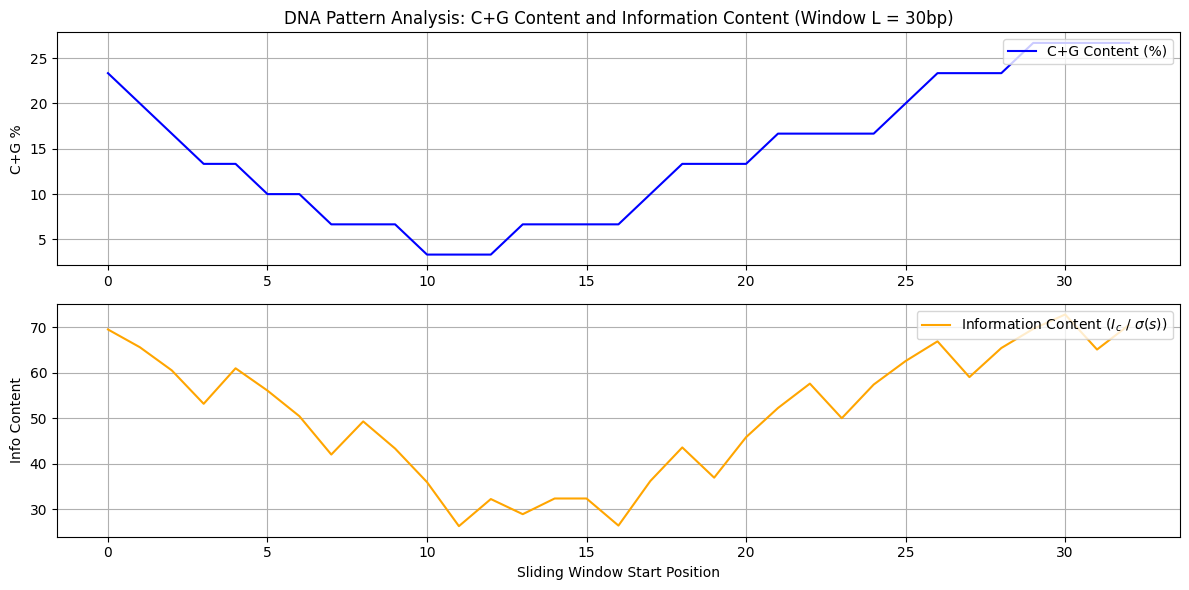

Center of Weight (C+G Pattern): 18.85
Center of Weight (Info Content Pattern): 16.78


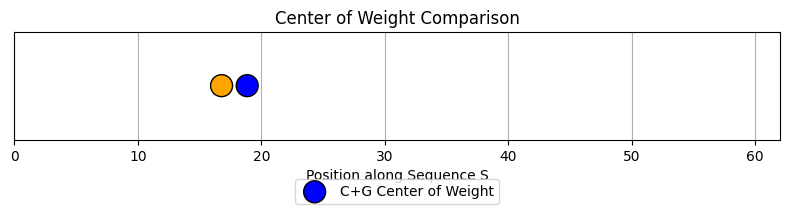

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

prefix = "CGGACTGATCTATCT"
middle_A = "A" * 27
suffix = "CGTAGCATCTATCGATCTAT"
S = prefix + middle_A + suffix

print(f"Complete Sequence S: {S}")
print(f"Sequence Length: {len(S)} bp")

window_size = 30


def compute_cg_content(seq):

  if not seq:
    return 0.0
  cg_count = seq.count("C") + seq.count("G") + seq.count("c") + seq.count("g")
  return (cg_count / len(seq)) * 100


def f(xi, x_ui):

  return 1 if xi == x_ui else 0


def compute_info_content(seq):

  L = len(seq)
  if L <= 1:
    return 0.0

  total_sum = 0.0
  for u in range(1, L):
    inner_sum = 0
    for i in range(L - u):
      inner_sum += f(seq[i], seq[i + u])
    avg_match = inner_sum / (L - u)
    total_sum += avg_match

  sigma = 100.0 - ((total_sum / (L - 1)) * 100.0)
  return sigma

cg_values = []
info_values = []

for i in range(len(S) - window_size + 1):
  window = S[i : i + window_size]
  cg_values.append(compute_cg_content(window))
  info_values.append(compute_info_content(window))

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(cg_values, label="C+G Content (%)", color="blue", linewidth=1.5)
plt.title(
    "DNA Pattern Analysis: C+G Content and Information Content (Window L = 30bp)"
)
plt.ylabel("C+G %")
plt.grid(True)
plt.legend(loc="upper right")

plt.subplot(2, 1, 2)
# FIX: Added 'r' prefix here to fix the escape sequence warning for \sigma
plt.plot(
    info_values,
    label=r"Information Content ($I_c$ / $\sigma(s)$)",
    color="orange",
    linewidth=1.5,
)
plt.xlabel("Sliding Window Start Position")
plt.ylabel("Info Content")
plt.grid(True)
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()


def center_of_weight(values):

  values = np.array(values)
  x = np.arange(len(values))
  total_weight = np.sum(values)
  if total_weight == 0:
    return 0.0
  return np.sum(x * values) / total_weight


cow_cg = center_of_weight(cg_values)
cow_info = center_of_weight(info_values)

print(f"Center of Weight (C+G Pattern): {cow_cg:.2f}")
print(f"Center of Weight (Info Content Pattern): {cow_info:.2f}")


plt.figure(figsize=(8, 2.5))
plt.scatter(
    [cow_cg, cow_info],
    [1, 1],
    color=["blue", "orange"],
    s=250,
    zorder=3,
    edgecolors="black",
)
plt.yticks([])
plt.xlim(0, len(S))
plt.title("Center of Weight Comparison")
plt.xlabel("Position along Sequence S")
plt.grid(True, axis="x")
plt.legend(
    ["C+G Center of Weight", "Info Content Center of Weight"],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.3),
    ncol=2,
)
plt.tight_layout()
plt.show()
